# TP 2 — AI52: Quantum Genetic Algorithm

Implementation of a Quantum Genetic Algorithm (QGA) for the 0–1 knapsack problem, following the TP handout:

1. Five knapsack instances covering the three required properties, with the exact optimum computed by dynamic programming.
2. A classical genetic algorithm (GA, from TP1) used as a baseline.
3. A QGA using the Han & Kim (2000) rotation policy (Table 1 of the handout).
4. A proposed improved rotation strategy (uncertainty-adaptive rotation), evaluated experimentally.
5. Comparison of solution quality and computation time while varying the number of generations, over several random seeds.

## 1. Imports

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. The five knapsack instances

The set must cover the three properties required by the handout:

- **I1 "high-value"**: all weights are equal, so the optimal solution keeps the items with the highest values.
- **I2 "low-weight"**: all values are equal, so the optimal solution keeps the items with the lowest weights.
- **I3, I4, I5**: random instances of increasing size, with total weight ≥ 3× capacity (checked for all five instances).

The exact optimum of each instance is computed with a dynamic-programming solver, so solution quality can be measured as a relative gap to the optimum.

In [2]:
class KnapsackProblem:
    def __init__(self, name, weights, values, capacity):
        self.name = name
        self.weights = np.array(weights, dtype=int)
        self.values = np.array(values, dtype=int)
        self.capacity = int(capacity)
        self.m = len(weights)

    def weight(self, x):
        return int(np.dot(self.weights, x))

    def value(self, x):
        return int(np.dot(self.values, x))

    def repair(self, P):
        # Greedy repair: remove items with the lowest value/weight ratio first
        P = P.copy()
        order = np.argsort(self.values / self.weights)
        W = P @ self.weights
        for j in np.nonzero(W > self.capacity)[0]:
            for i in order:
                if P[j, i] == 1:
                    P[j, i] = 0
                    W[j] -= self.weights[i]
                    if W[j] <= self.capacity:
                        break
        return P

    def evaluate(self, P):
        return (self.repair(P) @ self.values).astype(int)

    def dp_optimum(self):
        row = np.zeros(self.capacity + 1, dtype=int)
        for w, v in zip(self.weights, self.values):
            row[w:] = np.maximum(row[w:], row[:-w] + v)
        return int(row[self.capacity])


def make_instances(seed=52):
    rng = np.random.default_rng(seed)
    w = np.full(12, 2)
    v = rng.choice(np.arange(10, 100), 12, replace=False)
    i1 = KnapsackProblem("I1 high-value", w, v, 8)

    v = np.full(12, 10)
    w = rng.choice(np.arange(1, 61), 12, replace=False)
    i2 = KnapsackProblem("I2 low-weight", w, v, 8)

    w = rng.integers(1, 31, 16)
    v = rng.integers(1, 61, 16)
    i3 = KnapsackProblem("I3 random-16", w, v, int(w.sum()) // 4)

    w = rng.integers(2, 41, 24)
    v = rng.integers(5, 81, 24)
    i4 = KnapsackProblem("I4 random-24", w, v, int(w.sum()) * 2 // 7)

    w = rng.integers(1, 51, 40)
    v = rng.integers(1, 101, 40)
    i5 = KnapsackProblem("I5 random-40", w, v, int(w.sum()) // 3)

    return [i1, i2, i3, i4, i5]

In [3]:
instances = make_instances()

def top_values_solution(p, k):
    x = np.zeros(p.m, dtype=int)
    x[np.argsort(-p.values)[:k]] = 1
    return x

def low_weights_solution(p):
    x, cw = np.zeros(p.m, dtype=int), 0
    for i in np.argsort(p.weights):
        if cw + p.weights[i] <= p.capacity:
            x[i], cw = 1, cw + p.weights[i]
    return x

rows = []
for p in instances:
    opt = p.dp_optimum()
    prop1 = p.value(top_values_solution(p, 4)) == opt
    prop2 = p.value(low_weights_solution(p)) == opt
    rows.append({
        "instance": p.name, "items": p.m, "capacity": p.capacity,
        "total weight": int(p.weights.sum()),
        "sumW / C": round(p.weights.sum() / p.capacity, 2),
        "optimum": opt,
        "opt = highest values": prop1,
        "opt = lowest weights": prop2,
        "sumW >= 3C": p.weights.sum() >= 3 * p.capacity,
    })
pd.DataFrame(rows)

,instance,items,capacity,total weight,sumW / C,optimum,opt = highest values,opt = lowest weights,sumW >= 3C
0,I1 high-value,12,8,24,3.00,319,True,False,True
1,I2 low-weight,12,8,272,34.00,20,False,True,True
2,I3 random-16,16,54,216,4.00,340,False,False,True
3,I4 random-24,24,140,493,3.52,546,False,False,True
4,I5 random-40,40,324,972,3.00,1198,False,False,True


## 3. Classical genetic algorithm (baseline from TP1)

Binary chromosomes; each generation adds one mutated child and one uniform-crossover child per parent, then keeps the best half (truncation selection). Infeasible solutions are repaired (same rule as the QGA, for a fair comparison).

In [4]:
def genetic_algorithm(problem, pop_size=30, generations=100, rng=None):
    m = problem.m
    pop = problem.repair(rng.integers(0, 2, (pop_size, m)))
    for _ in range(generations):
        children = []
        for i in range(pop_size):
            a = pop[i].copy()
            for k in rng.choice(m, size=3, replace=False):
                a[k] = 1 - a[k]
            b = pop[i].copy()
            sw = rng.random(m) < 0.5
            b[sw] = pop[(i + 1) % pop_size][sw]
            children += [a, b]
        pop = problem.repair(np.vstack([pop, children]))
        pop = pop[np.argsort(-problem.evaluate(pop))[:pop_size]]
    return pop[np.argmax(problem.evaluate(pop))]

## 4. Quantum genetic algorithm

A quantum chromosome is a vector of qubit angles $\theta_i$, with $\alpha_i = \\cos(\theta_i/2)$ and $\beta_i = \\sin(\theta_i/2)$, initialized at $\theta = \pi/2$ ($\alpha = \beta = 1/\\sqrt{2}$, uniform superposition).

- **Observation**: bit $x_i = 1$ with probability $\beta_i^2 = \sin^2(\theta_i/2)$.
- **Rotation gate** $U(\gamma)$: the update $[\alpha', \beta']^T = U(\gamma)[\alpha, \beta]^T$ shifts the angle by $\theta \leftarrow \theta + 2\gamma$; a positive $\gamma$ increases $P(1)$.
- Infeasible solutions are repaired before evaluation.

### Han–Kim rotation policy (Table 1 of the handout)

The angle is $\gamma = s \times \Delta\gamma$ where $\Delta\gamma$ and the sign $s$ are read from the table, using the current bit $x_{j,i}$, the best bit $b_i$, the fitness comparison $f(p_j^t) \geq f(b^t)$, and the sign of $\alpha\beta$. For the $\pm 1$ edge cases we take the sign of the non-zero amplitude ($s = \mathrm{sign}(\beta)$ when $\alpha = 0$, $s = \mathrm{sign}(\alpha)$ when $\beta = 0$).

In [5]:
def observe(theta, rng):
    return (rng.random(theta.shape) < np.sin(theta / 2) ** 2).astype(int)


def sign_lookup(alpha, beta, s_neg, s_pos, s_a0, s_b0):
    # s_neg / s_pos for alpha*beta < 0 / > 0; +-1 cases use the non-zero amplitude's sign
    eps = 1e-12
    a0, b0 = np.abs(alpha) < eps, np.abs(beta) < eps
    s = np.where(alpha * beta < 0, s_neg, s_pos)
    s = np.where(a0 & ~b0, s_a0 * np.sign(beta), s)
    s = np.where(b0 & ~a0, s_b0 * np.sign(alpha), s)
    return np.where(a0 & b0, 0.0, s)


def han_kim_gamma(X, best, ge, theta, mag):
    # mag scales delta_gamma (1.0 for the plain handout policy)
    x, b = X, best[None, :]
    alpha, beta = np.cos(theta / 2), np.sin(theta / 2)
    gamma = np.zeros_like(theta)
    c = (x == 0) & (b == 1) & ge
    gamma[c] = 0.05 * np.pi * mag[c] * sign_lookup(alpha[c], beta[c], -1, 1, 1, 0)
    c = (x == 1) & (b == 0) & ~ge
    gamma[c] = 0.01 * np.pi * mag[c] * sign_lookup(alpha[c], beta[c], -1, 1, 1, 0)
    c = (x == 1) & (b == 0) & ge
    gamma[c] = 0.025 * np.pi * mag[c] * sign_lookup(alpha[c], beta[c], 1, -1, 0, 1)
    c = (x == 1) & (b == 1) & ~ge
    gamma[c] = 0.05 * np.pi * mag[c] * sign_lookup(alpha[c], beta[c], 1, -1, 0, 1)
    c = (x == 1) & (b == 1) & ge
    gamma[c] = 0.025 * np.pi * mag[c] * sign_lookup(alpha[c], beta[c], 1, -1, 0, 1)
    return gamma


def qga(problem, pop_size=30, generations=100, rng=None, strategy="table"):
    m = problem.m
    theta = np.full((pop_size, m), np.pi / 2)
    P = problem.repair(observe(theta, rng))
    F = problem.evaluate(P)
    bi = int(np.argmax(F))
    best, best_f = P[bi].copy(), int(F[bi])
    for _ in range(generations):
        ge = (F >= best_f)[:, None]
        mag = np.ones_like(theta) if strategy == "table" else uncertainty_mag(theta)
        gamma = han_kim_gamma(P, best, ge, theta, mag)
        theta = (theta + 2 * gamma) % (2 * np.pi)
        P = problem.repair(observe(theta, rng))
        F = problem.evaluate(P)
        bi = int(np.argmax(F))
        if F[bi] > best_f:
            best, best_f = P[bi].copy(), int(F[bi])
    return best

## 5. Proposed rotation strategy: uncertainty-adaptive rotation

The plain policy collapses quickly: once a chromosome matches the best solution bit-wise, every $\Delta\gamma$ is 0 and the population freezes around a mediocre solution (premature convergence).

**Proposed strategy.** Keep the signs and base magnitudes of Table 1, but scale each qubit's rotation by its *uncertainty*:

$$\gamma_{j,i} = s_{j,i} \times \Delta\gamma_{j,i} \times \underbrace{(1 - 2|\alpha_{j,i}\beta_{j,i}|)}_{\\in\ [0,1]}$$

$|\alpha\beta| = |\sin\theta|/2$ is maximal (0.5) when the qubit is decided ($P(1)$ near 0 or 1) and zero at the uniform superposition. Uncertain qubits therefore rotate at full strength (they still carry exploratory potential), while qubits the algorithm has already decided about are barely perturbed. This preserves diversity where it is useful and protects converged coordinates, at no extra computational cost.

In [6]:
def uncertainty_mag(theta):
    return 1 - 2 * np.abs(np.cos(theta / 2) * np.sin(theta / 2))

## 6. Experimental comparison

Protocol: 5 instances × generations {20, 50, 100, 200} × 10 random seeds, population size 30 for all algorithms. Metrics: best value found (relative gap to the DP optimum) and wall-clock time.

In [7]:
GENERATIONS = [20, 50, 100, 200]
SEEDS = range(10)
POP_SIZE = 30

ALGOS = {
    "GA": lambda p, g, rng: genetic_algorithm(p, POP_SIZE, g, rng),
    "QGA": lambda p, g, rng: qga(p, POP_SIZE, g, rng, strategy="table"),
    "QGA-U": lambda p, g, rng: qga(p, POP_SIZE, g, rng, strategy="uncertainty"),
}

results = {a: {p.name: {g: [] for g in GENERATIONS} for p in instances} for a in ALGOS}
times = {a: {p.name: {g: [] for g in GENERATIONS} for p in instances} for a in ALGOS}

t_start = time.perf_counter()
for p in instances:
    opt = p.dp_optimum()
    for g in GENERATIONS:
        for name, algo in ALGOS.items():
            for s in SEEDS:
                rng = np.random.default_rng(1000 + s)
                t0 = time.perf_counter()
                x = algo(p, g, rng)
                results[name][p.name][g].append(100 * (opt - p.value(x)) / opt)
                times[name][p.name][g].append(time.perf_counter() - t0)
print(f"total experiment time: {time.perf_counter() - t_start:.1f}s")

total experiment time: 14.6s


### Solution quality (gap to optimum, % — lower is better)

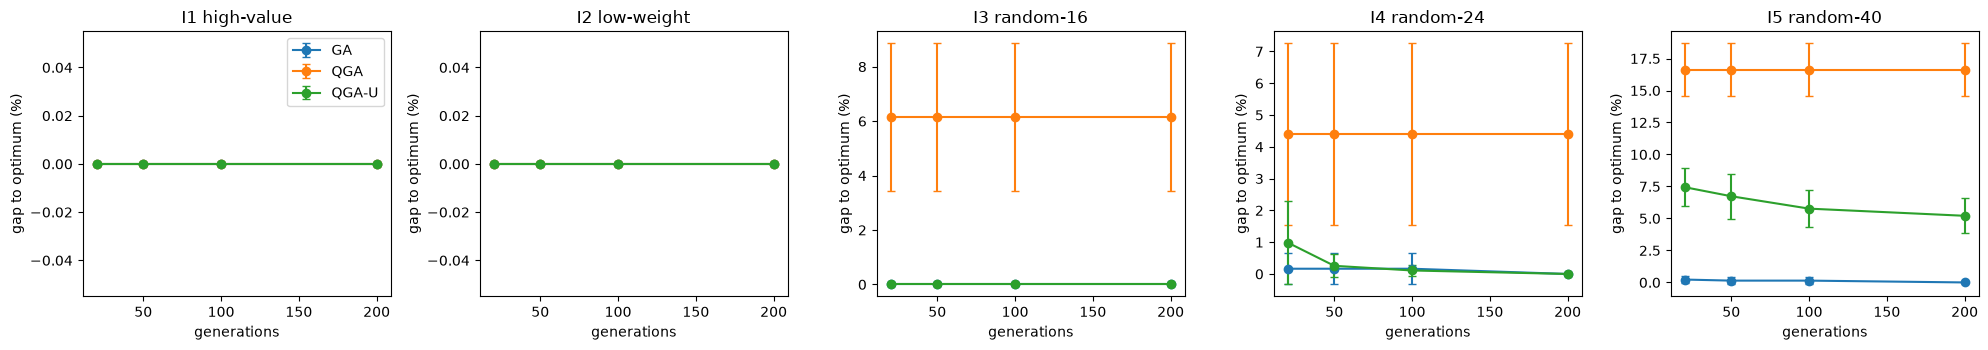

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, p in zip(axes, instances):
    for name in ALGOS:
        means = [np.mean(results[name][p.name][g]) for g in GENERATIONS]
        stds = [np.std(results[name][p.name][g]) for g in GENERATIONS]
        ax.errorbar(GENERATIONS, means, yerr=stds, marker="o", capsize=3, label=name)
    ax.set_title(p.name)
    ax.set_xlabel("generations")
    ax.set_ylabel("gap to optimum (%)")
axes[0].legend()
plt.tight_layout()
plt.show()

### Computation time (s)

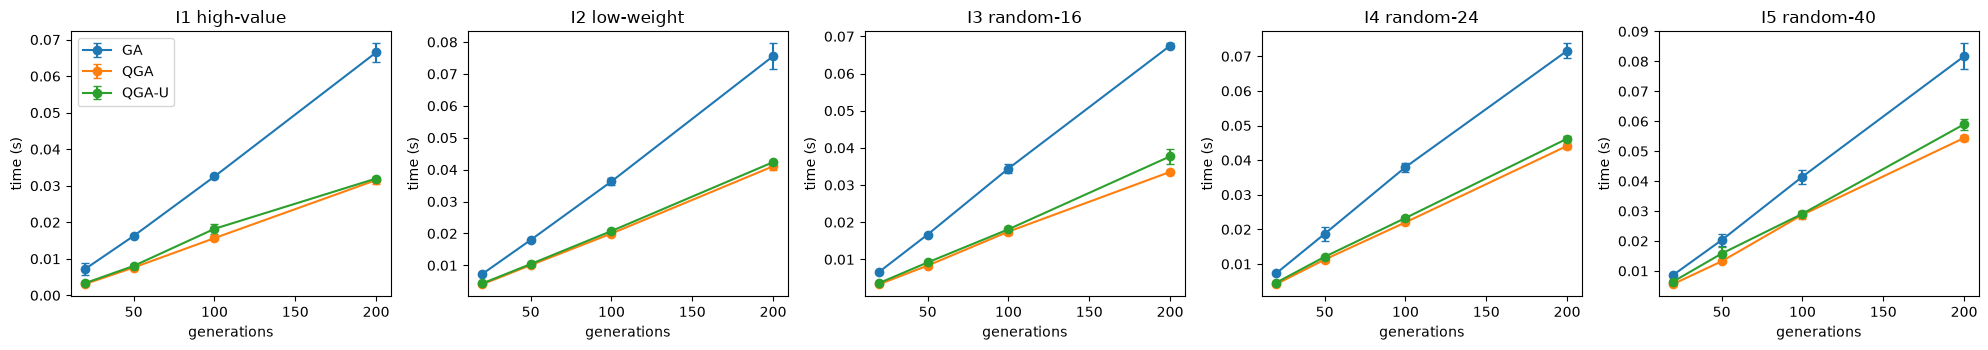

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, p in zip(axes, instances):
    for name in ALGOS:
        means = [np.mean(times[name][p.name][g]) for g in GENERATIONS]
        stds = [np.std(times[name][p.name][g]) for g in GENERATIONS]
        ax.errorbar(GENERATIONS, means, yerr=stds, marker="o", capsize=3, label=name)
    ax.set_title(p.name)
    ax.set_xlabel("generations")
    ax.set_ylabel("time (s)")
axes[0].legend()
plt.tight_layout()
plt.show()

### Summary tables (mean over 10 seeds)

In [10]:
for metric, store in [("gap to optimum (%)", results), ("time (s)", times)]:
    rows = []
    for p in instances:
        for g in GENERATIONS:
            row = {"instance": p.name, "generations": g}
            for name in ALGOS:
                row[name] = round(np.mean(store[name][p.name][g]), 2)
            rows.append(row)
    print(f"--- {metric} ---")
    print(pd.DataFrame(rows).to_string(index=False))
    print()

--- gap to optimum (%) ---
     instance  generations   GA   QGA  QGA-U
I1 high-value           20 0.00  0.00   0.00
I1 high-value           50 0.00  0.00   0.00
I1 high-value          100 0.00  0.00   0.00
I1 high-value          200 0.00  0.00   0.00
I2 low-weight           20 0.00  0.00   0.00
I2 low-weight           50 0.00  0.00   0.00
I2 low-weight          100 0.00  0.00   0.00
I2 low-weight          200 0.00  0.00   0.00
 I3 random-16           20 0.00  6.15   0.00
 I3 random-16           50 0.00  6.15   0.00
 I3 random-16          100 0.00  6.15   0.00
 I3 random-16          200 0.00  6.15   0.00
 I4 random-24           20 0.16  4.40   0.99
 I4 random-24           50 0.16  4.40   0.26
 I4 random-24          100 0.16  4.40   0.11
 I4 random-24          200 0.00  4.40   0.00
 I5 random-40           20 0.23 16.64   7.45
 I5 random-40           50 0.14 16.64   6.74
 I5 random-40          100 0.14 16.64   5.77
 I5 random-40          200 0.00 16.64   5.21

--- time (s) ---
     insta

## 7. Results and discussion

**Solution quality.**
- On the two structured instances (I1, I2), all three algorithms reach the optimum, even with 20 generations: the strong regularity (equal weights / equal values) makes them easy.
- On the random instances, the baseline QGA *plateaus*: its mean gap is identical at 20 and 200 generations (6.2 % on I3, 4.4 % on I4, 16.6 % on I5). Once its chromosomes match the best solution on the "0" bits, the table prescribes $\\Delta\\gamma = 0$ forever and the search freezes — more generations buy nothing.
- The uncertainty-adaptive rotation (QGA-U) fixes most of this: gaps keep decreasing with the generation budget (I4: 1.0 % -> 0.0 %, I5: 7.5 % -> 5.2 %), it reaches the exact optimum on I3 in every run, and it is never worse than the baseline. GA keeps the best overall quality on the largest instance (I5: 0.2-0.0 %).

**Computation time.**
- GA costs about 1.5-2x more time than the QGA variants at equal generation count, because each generation builds and sorts 3x the population, while the QGA only rotates amplitudes and re-observes (fully vectorized).
- All curves are linear in the number of generations, as expected.

**Why the uncertainty-adaptive rotation helps.** $|\\alpha\\beta| = |\\sin\\theta|/2$ is large only for qubits whose sampling probability is already decided. Scaling the rotation by $1 - 2|\\alpha\\beta|$ keeps those qubits almost frozen (consistent with the best solution) while uncertain qubits rotate at full strength, so the population retains exploratory power instead of collapsing. The gain is largest exactly where the baseline freezes the most (large instances, long runs).

**Trade-off.** QGA-U costs the same time as the baseline QGA (one extra vectorized expression per generation) while closing a large part of the quality gap to GA; GA still dominates in quality on large instances but at a higher computational cost per generation.